In [2]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
import statsmodels as sm

nomes_colunas = [
    'cod_municipio', 
    'nome_municipio',
    'perc_doc_sobrecarga',          
    'taxa_informal', 
    'taxa_climatizacao', 
    'taxa_internet',
    'taxa_lab',
    'media_alunos_por_sala',
    'renda_pc',
    'evasao',
    'tx_repet' 
]

pasta_dados = Path('C:\\Users\\patri\\PY_LOCAL\\TESTES_TCC_2\\data')
caminho_arquivo = pasta_dados / 'TESTE_ML_COM_TAXAS_INFRA.csv'
df = pd.read_csv(caminho_arquivo, sep=';', header=None, names=nomes_colunas)

display(df)

,cod_municipio,nome_municipio,perc_doc_sobrecarga,taxa_informal,taxa_climatizacao,taxa_internet,taxa_lab,media_alunos_por_sala,renda_pc,evasao,tx_repet
0,4200051,Abdon Batista,35.7,"52,34","83,33","83,33",50,"23,8",2127.38,"2,8","3,8"
1,4200101,Abelardo Luz,25.0,"34,26",90,90,65,"23,8",1685.84,"2,9","11,9"
2,4200200,Agrolândia,25.1,"24,39","93,33",100,40,"22,8",1683.01,"4,9","5,9"
3,4200309,Agronômica,29.7,"32,44",100,100,0,"18,7",2206.89,3,"8,1"
4,4200408,Água Doce,15.4,"27,45","58,33","91,67","33,33","21,9",2200.72,"3,2",4
...,...,...,...,...,...,...,...,...,...,...,...
290,4219408,Witmarsum,30.0,"31,1",100,100,50,22,2324.29,"3,8","3,1"
291,4219507,Xanxerê,18.5,"22,31","86,11","97,22","33,33","25,4",2120.34,5,"15,5"
292,4219606,Xavantina,16.7,"50,1",100,100,"71,43",19,2639.27,"2,1","4,1"
293,4219705,Xaxim,19.9,"22,94","78,26","86,96","47,83",22,1900.05,"6,7",16


In [3]:
colunas_ml = ['taxa_informal','media_alunos_por_sala','tx_repet','evasao', 'renda_pc','taxa_climatizacao','taxa_internet','taxa_lab']

for col in colunas_ml:
    df[col] = df[col].astype(str).str.replace(',', '.').astype(float)
    df[col] = df[col].round(2)

display(df)

,cod_municipio,nome_municipio,perc_doc_sobrecarga,taxa_informal,taxa_climatizacao,taxa_internet,taxa_lab,media_alunos_por_sala,renda_pc,evasao,tx_repet
0,4200051,Abdon Batista,35.7,52.34,83.33,83.33,50.00,23.8,2127.38,2.8,3.8
1,4200101,Abelardo Luz,25.0,34.26,90.00,90.00,65.00,23.8,1685.84,2.9,11.9
2,4200200,Agrolândia,25.1,24.39,93.33,100.00,40.00,22.8,1683.01,4.9,5.9
3,4200309,Agronômica,29.7,32.44,100.00,100.00,0.00,18.7,2206.89,3.0,8.1
4,4200408,Água Doce,15.4,27.45,58.33,91.67,33.33,21.9,2200.72,3.2,4.0
...,...,...,...,...,...,...,...,...,...,...,...
290,4219408,Witmarsum,30.0,31.10,100.00,100.00,50.00,22.0,2324.29,3.8,3.1
291,4219507,Xanxerê,18.5,22.31,86.11,97.22,33.33,25.4,2120.34,5.0,15.5
292,4219606,Xavantina,16.7,50.10,100.00,100.00,71.43,19.0,2639.27,2.1,4.1
293,4219705,Xaxim,19.9,22.94,78.26,86.96,47.83,22.0,1900.05,6.7,16.0


In [4]:
print(df[['perc_doc_sobrecarga', 'taxa_informal', 'taxa_climatizacao', 'taxa_internet', 'taxa_lab', 'media_alunos_por_sala',
'renda_pc', 'tx_repet', 'evasao']].dtypes)

perc_doc_sobrecarga      float64
taxa_informal            float64
taxa_climatizacao        float64
taxa_internet            float64
taxa_lab                 float64
media_alunos_por_sala    float64
renda_pc                 float64
tx_repet                 float64
evasao                   float64
dtype: object


In [ ]:
print(df.isna().sum());

print((df == 0).sum());

print("Linhas duplicadas:", df.duplicated().sum());

resumo = (
    df['enquadro']
    .value_counts()
    .rename_axis('enquadro')
    .reset_index(name='quantidade')
)

resumo['percentual'] = (resumo['quantidade'] / len(df) * 100).round(2)
resumo['enquadro'] = resumo['enquadro'].map({0: 'Baixo risco', 1: 'Alto risco'})

display(resumo)

cod_municipio            0
nome_municipio           0
perc_doc_sobrecarga      0
taxa_informal            0
taxa_climatizacao        0
taxa_internet            0
taxa_lab                 0
media_alunos_por_sala    0
renda_pc                 0
evasao                   0
tx_repet                 0
dtype: int64
cod_municipio             0
nome_municipio            0
perc_doc_sobrecarga       3
taxa_informal             0
taxa_climatizacao         0
taxa_internet             0
taxa_lab                  8
media_alunos_por_sala     0
renda_pc                  0
evasao                   14
tx_repet                 15
dtype: int64
Linhas duplicadas: 0


In [6]:
display(df[['perc_doc_sobrecarga', 'taxa_informal', 'taxa_climatizacao', 'taxa_internet', 'taxa_lab','media_alunos_por_sala',
'renda_pc', 'tx_repet', 'evasao']].describe());

,perc_doc_sobrecarga,taxa_informal,taxa_climatizacao,taxa_internet,taxa_lab,media_alunos_por_sala,renda_pc,tx_repet,evasao
count,295.000000,295.000000,295.000000,295.000000,295.000000,295.000000,295.000000,295.000000,295.000000
mean,29.055932,34.822712,77.184508,83.142305,37.392339,21.809831,1954.694847,7.828136,4.038983
std,11.105681,11.873264,18.609427,14.348670,20.182431,4.906979,429.623841,4.497322,2.585978
min,0.000000,15.100000,7.690000,21.430000,0.000000,6.700000,1031.920000,0.000000,0.000000
25%,21.700000,24.885000,68.990000,75.000000,21.825000,18.350000,1674.240000,4.700000,2.200000
50%,29.100000,33.070000,80.000000,85.710000,37.500000,21.900000,1899.350000,7.500000,3.700000
75%,35.700000,43.675000,90.910000,93.845000,50.000000,25.800000,2168.935000,10.750000,5.200000
max,70.500000,73.830000,100.000000,100.000000,100.000000,34.200000,3636.130000,23.800000,13.200000


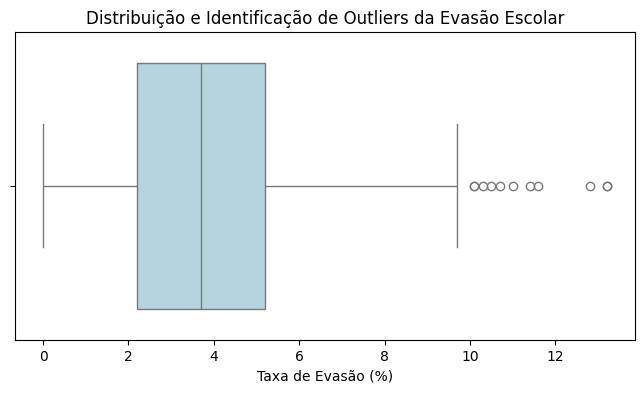

In [7]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['evasao'], color='lightblue')
plt.title('Distribuição e Identificação de Outliers da Evasão Escolar')
plt.xlabel('Taxa de Evasão (%)')
plt.show()

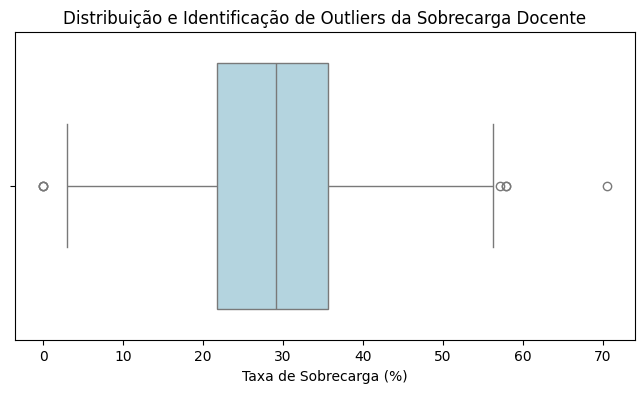

In [8]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['perc_doc_sobrecarga'], color='lightblue')
plt.title('Distribuição e Identificação de Outliers da Sobrecarga Docente')
plt.xlabel('Taxa de Sobrecarga (%)')
plt.show()

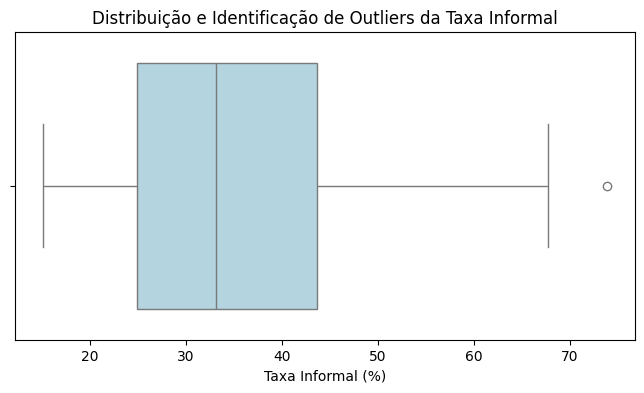

In [9]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['taxa_informal'], color='lightblue')
plt.title('Distribuição e Identificação de Outliers da Taxa Informal')
plt.xlabel('Taxa Informal (%)')
plt.show()

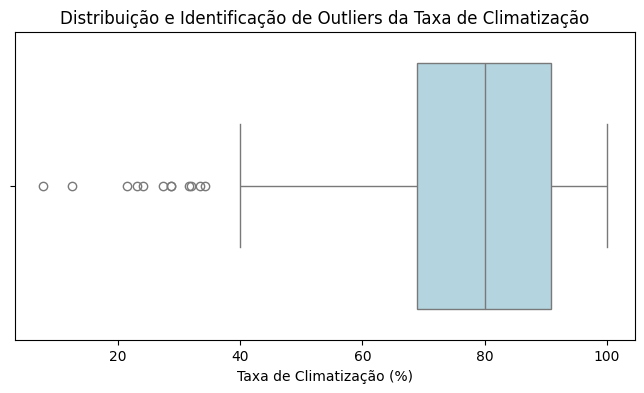

In [10]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['taxa_climatizacao'], color='lightblue')
plt.title('Distribuição e Identificação de Outliers da Taxa de Climatização')
plt.xlabel('Taxa de Climatização (%)')
plt.show()

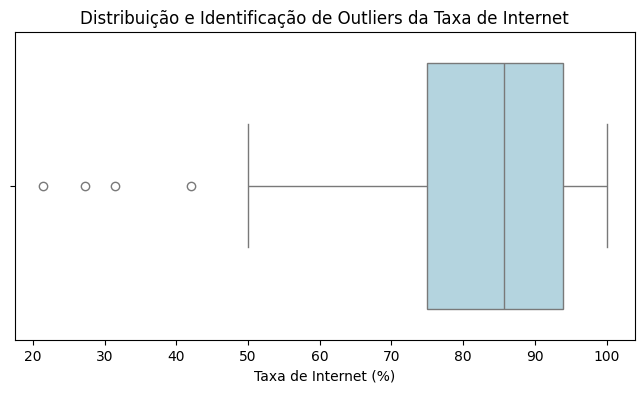

In [11]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['taxa_internet'], color='lightblue')
plt.title('Distribuição e Identificação de Outliers da Taxa de Internet')
plt.xlabel('Taxa de Internet (%)')
plt.show()

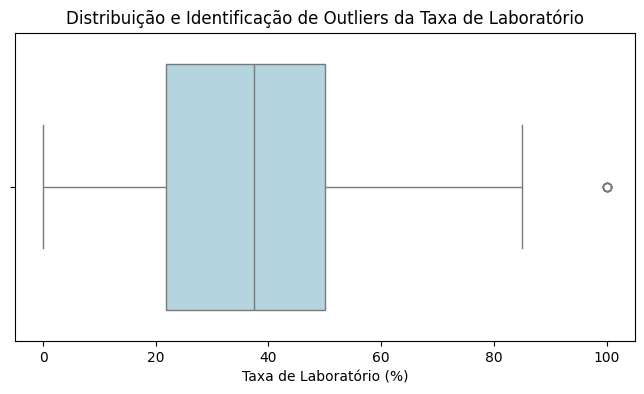

In [12]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['taxa_lab'], color='lightblue')
plt.title('Distribuição e Identificação de Outliers da Taxa de Laboratório')
plt.xlabel('Taxa de Laboratório (%)')
plt.show()

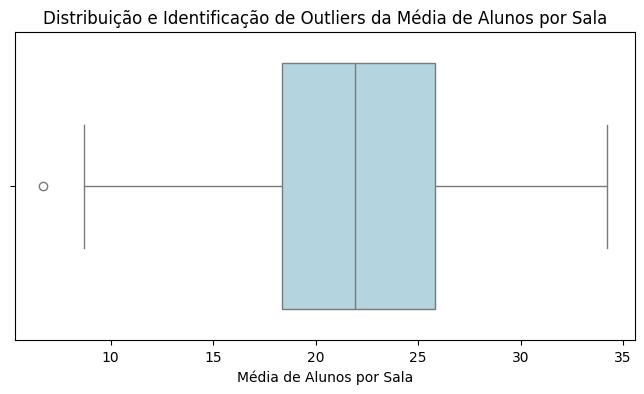

In [13]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['media_alunos_por_sala'], color='lightblue')
plt.title('Distribuição e Identificação de Outliers da Média de Alunos por Sala')
plt.xlabel('Média de Alunos por Sala')
plt.show()

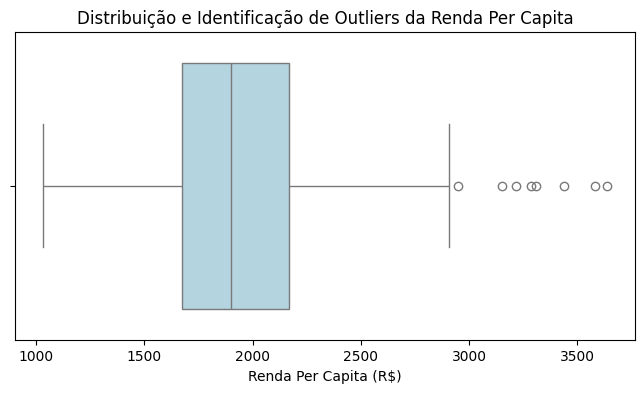

In [14]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['renda_pc'], color='lightblue')
plt.title('Distribuição e Identificação de Outliers da Renda Per Capita')
plt.xlabel('Renda Per Capita (R$)')
plt.show()

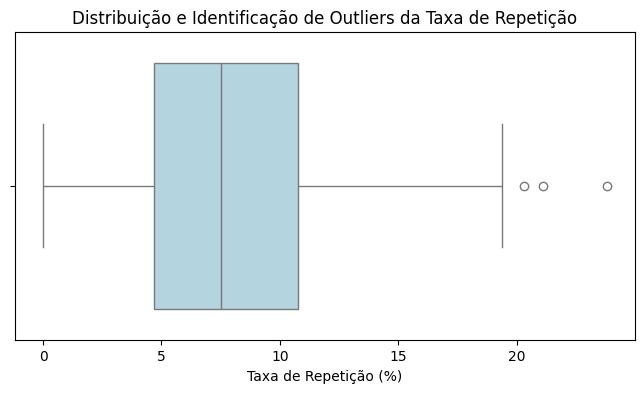

In [15]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['tx_repet'], color='lightblue')
plt.title('Distribuição e Identificação de Outliers da Taxa de Repetição')
plt.xlabel('Taxa de Repetição (%)')
plt.show()

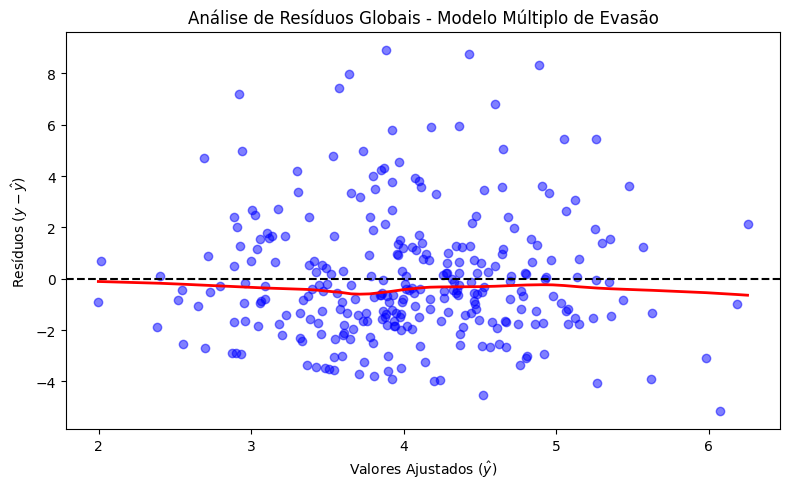

In [16]:
colunas_df = ['perc_doc_sobrecarga', 'taxa_informal', 'taxa_climatizacao', 'taxa_internet', 'taxa_lab','media_alunos_por_sala',
             'renda_pc', 'tx_repet']
colunas_X = df[colunas_df]
X = colunas_X
y = df['evasao']

model = LinearRegression()
model.fit(X,y)
y_pred = model.predict(X)

residuos = y - y_pred

plt.figure(figsize=(8, 5))
sns.regplot(
    x=y_pred, 
    y=residuos, 
    lowess=True, 
    scatter_kws={'color': 'blue', 'alpha': 0.5}, 
    line_kws={'color': 'red', 'lw': 2}
)
plt.axhline(0, color='black', linestyle='--')
plt.xlabel("Valores Ajustados ($\hat{y}$)")
plt.ylabel("Resíduos ($y - \hat{y}$)")
plt.title("Análise de Resíduos Globais - Modelo Múltiplo de Evasão")
plt.tight_layout()
plt.show()

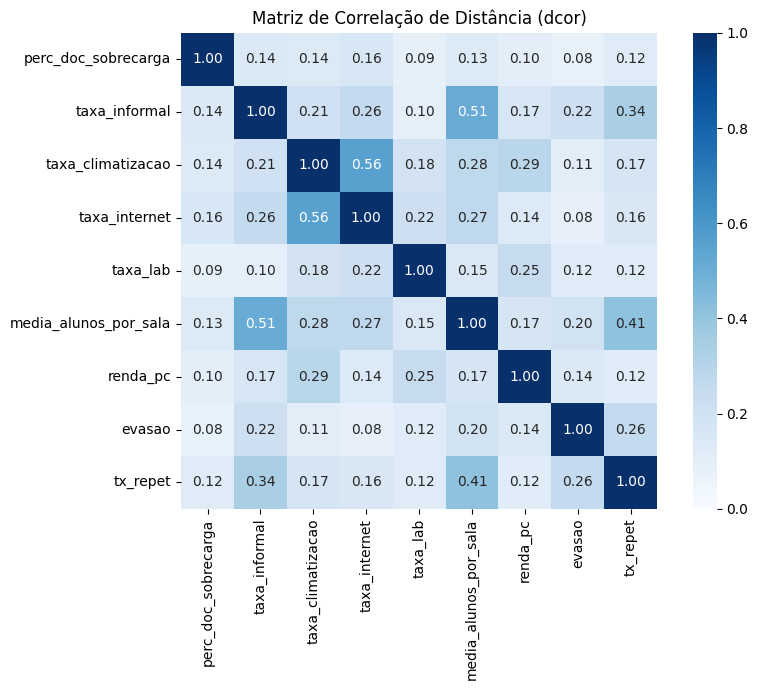

In [ ]:
import dcor

numericas = df.select_dtypes(include='number').drop(columns=['cod_municipio'], errors='ignore')

numericas_clean = numericas.dropna()

cols = numericas_clean.columns
corr_dcor = pd.DataFrame(index=cols, columns=cols, dtype=float)

# 3. Preencher a matriz com o cálculo de Distance Correlation par a par
for col1 in cols:
    for col2 in cols:
        if col1 == col2:
            corr_dcor.loc[col1, col2] = 1.0
        else:
            corr_dcor.loc[col1, col2] = dcor.distance_correlation(
                numericas_clean[col1].values, 
                numericas_clean[col2].values
            )

plt.figure(figsize=(9, 7))
sns.heatmap(
    corr_dcor, 
    annot=True, 
    fmt='.2f', 
    cmap='Blues',   
    vmin=0, 
    vmax=1, 
    square=True
)
plt.title('Matriz de Correlação de Distância (dcor)')
plt.tight_layout()
plt.show()